# DS-471 Machine Learning Project: Dry Bean Classification

This notebook classifies dry beans into seven varieties (BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA) using the [UCI Dry Bean dataset](https://archive.ics.uci.edu/dataset/602/dry+bean). It covers data cleaning and EDA, feature selection and engineering, a stratified 70/15/15 split, three models (Logistic Regression, Random Forest, and a PyTorch MLP neural network), hyperparameter tuning, training/validation analysis, and the final test-set comparison.

## 1. Load the dataset

The dataset is loaded from a local file if one is available; otherwise it is downloaded from the UCI repository. Column names are standardized (`AspectRation` → `AspectRatio`), and we confirm that all 16 input features are numerical.

In [ ]:
import sys, subprocess, importlib.util
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

def load_dry_bean():
    # Try the uploaded file first, then load the UCI dataset if needed.
    import os
    for path in ["Dry_Bean_Dataset.xlsx", "Dry_Bean_Dataset(1).xlsx", "Dry_Bean_Dataset.csv",
                 "/content/Dry_Bean_Dataset.xlsx", "/content/Dry_Bean_Dataset(1).xlsx", "/content/Dry_Bean_Dataset.csv"]:
        if os.path.exists(path):
            print(f"Loading local dataset: {path}")
            return pd.read_excel(path) if path.endswith("xlsx") else pd.read_csv(path)
    for path in ["Dry_Bean_Dataset.arff", "Dry_Bean_Dataset(1).arff",
                 "/content/Dry_Bean_Dataset.arff", "/content/Dry_Bean_Dataset(1).arff"]:
        if os.path.exists(path):
            from scipy.io import arff
            data, _ = arff.loadarff(path)
            loaded = pd.DataFrame(data)
            loaded["Class"] = loaded["Class"].str.decode("utf-8")
            loaded = loaded.rename(columns={"roundness": "Roundness"})
            print(f"Loading local dataset: {path}")
            return loaded
    if importlib.util.find_spec("ucimlrepo") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "ucimlrepo"])
    from ucimlrepo import fetch_ucirepo
    dry_bean = fetch_ucirepo(id=602)
    return pd.concat([dry_bean.data.features.copy(), dry_bean.data.targets.copy()], axis=1)

df_original = load_dry_bean()
df = df_original.copy()
df.columns = [str(c).strip() for c in df.columns]
if "roundness" in df.columns and "Roundness" not in df.columns:
    df.rename(columns={"roundness": "Roundness"}, inplace=True)
if "AspectRation" in df.columns and "AspectRatio" not in df.columns:
    df.rename(columns={"AspectRation": "AspectRatio"}, inplace=True)

target = "Class"
assert target in df.columns, "Expected UCI target column 'Class'."
features = [c for c in df.columns if c != target]
numeric_features = df[features].select_dtypes(include=np.number).columns.tolist()
assert len(features) == len(numeric_features) == 16, "Check that all 16 input features are numeric."
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 2. Understand the dataset

First, we check the number of rows and columns, data types, class labels, and basic statistics to get an idea of what the dataset contains.


In [ ]:
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Input features:", len(features))
print("Target:", target)
print("Classes:", sorted(df[target].dropna().unique()))

display(pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique()
}))
display(df[features].describe().T)

Rows: 13611
Columns: 17
Input features: 16
Target: Class
Classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


,Data type,Missing values,Unique values
Area,int64,0,12011
Perimeter,float64,0,13351
MajorAxisLength,float64,0,13543
MinorAxisLength,float64,0,13543
AspectRatio,float64,0,13543
Eccentricity,float64,0,13543
ConvexArea,int64,0,12066
EquivDiameter,float64,0,12011
Extent,float64,0,13535
Solidity,float64,0,13522


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


## 3. Data cleaning

Before training a model, we need to check for missing values, duplicates, incorrect data types, and possible outliers.


### 3.1 Missing values

We count the missing values in each column to see whether anything needs to be filled in or removed.


In [ ]:
missing = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing percentage": (df.isna().mean() * 100).round(2)
})
display(missing)
print("Total missing values:", int(df.isna().sum().sum()))

,Missing count,Missing percentage
Area,0,0.0
Perimeter,0,0.0
MajorAxisLength,0,0.0
MinorAxisLength,0,0.0
AspectRatio,0,0.0
Eccentricity,0,0.0
ConvexArea,0,0.0
EquivDiameter,0,0.0
Extent,0,0.0
Solidity,0,0.0


Total missing values: 0


### 3.2 Duplicate records

We check for identical rows and remove duplicates so the same record is not counted more than once.


In [ ]:
duplicate_count = int(df.duplicated().sum())
print("Exact duplicate rows:", duplicate_count)

# Keep the first copy and remove repeated exact rows
df = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df.shape)

Exact duplicate rows: 68
Shape after removing duplicates: (13543, 17)


### 3.3 Inconsistent values and data types

We check for empty class labels, extra spaces, and non-numeric values in the input columns.


In [ ]:
labels = df[target].astype("string")
print("Blank target labels:", int(labels.str.strip().eq("").sum()))
print("Labels with extra spaces:", int((labels != labels.str.strip()).sum()))
print("Target classes:", sorted(labels.dropna().str.strip().unique()))

non_numeric = {}
for col in features:
    converted = pd.to_numeric(df[col], errors="coerce")
    non_numeric[col] = int((converted.isna() & df[col].notna()).sum())
display(pd.Series(non_numeric,  name="Non-numeric values").to_frame())

Blank target labels: 0
Labels with extra spaces: 0
Target classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


,Non-numeric values
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRatio,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


### 3.4 Outliers (IQR method)

We use the IQR method to find unusual values. We keep these records because different bean types can naturally have different sizes and shapes.


In [ ]:
outlier_rows = []
for col in numeric_features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((df[col] < lower) | (df[col] > upper)).sum())
    outlier_rows.append({
        "Feature": col,
        "Outlier count": count,
        "Outlier percentage": round(count / len(df) * 100, 2)
    })

display(pd.DataFrame(outlier_rows).sort_values("Outlier count", ascending=False))

,Feature,Outlier count,Outlier percentage
5,Eccentricity,833,6.15
9,Solidity,774,5.72
15,ShapeFactor4,760,5.61
3,MinorAxisLength,567,4.19
0,Area,551,4.07
6,ConvexArea,549,4.05
12,ShapeFactor1,533,3.94
7,EquivDiameter,526,3.88
1,Perimeter,500,3.69
4,AspectRatio,485,3.58


## 4. Exploratory Data Analysis (EDA)

Next, we use tables and plots to see how the bean classes and numerical features are distributed.


### 4.1 Class distribution

We count the records in each bean class to check whether some classes are more common than others.


,Count,Percentage
Class,,
DERMASON,3546,26.18
SIRA,2636,19.46
SEKER,2027,14.97
HOROZ,1860,13.73
CALI,1630,12.04
BARBUNYA,1322,9.76
BOMBAY,522,3.85


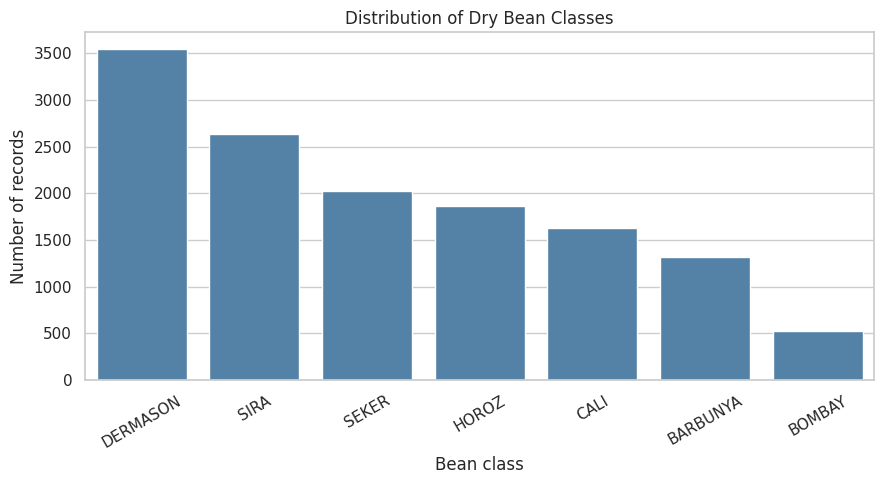

In [ ]:
class_counts = df[target].value_counts()
display(pd.DataFrame({
    "Count": class_counts,
    "Percentage": (class_counts / len(df) * 100).round(2)
}))

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x=target, order=class_counts.index, color="steelblue")
plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean class")
plt.ylabel("Number of records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 4.2 Numerical feature distributions

These histograms show the range and distribution of the 16 numerical features.


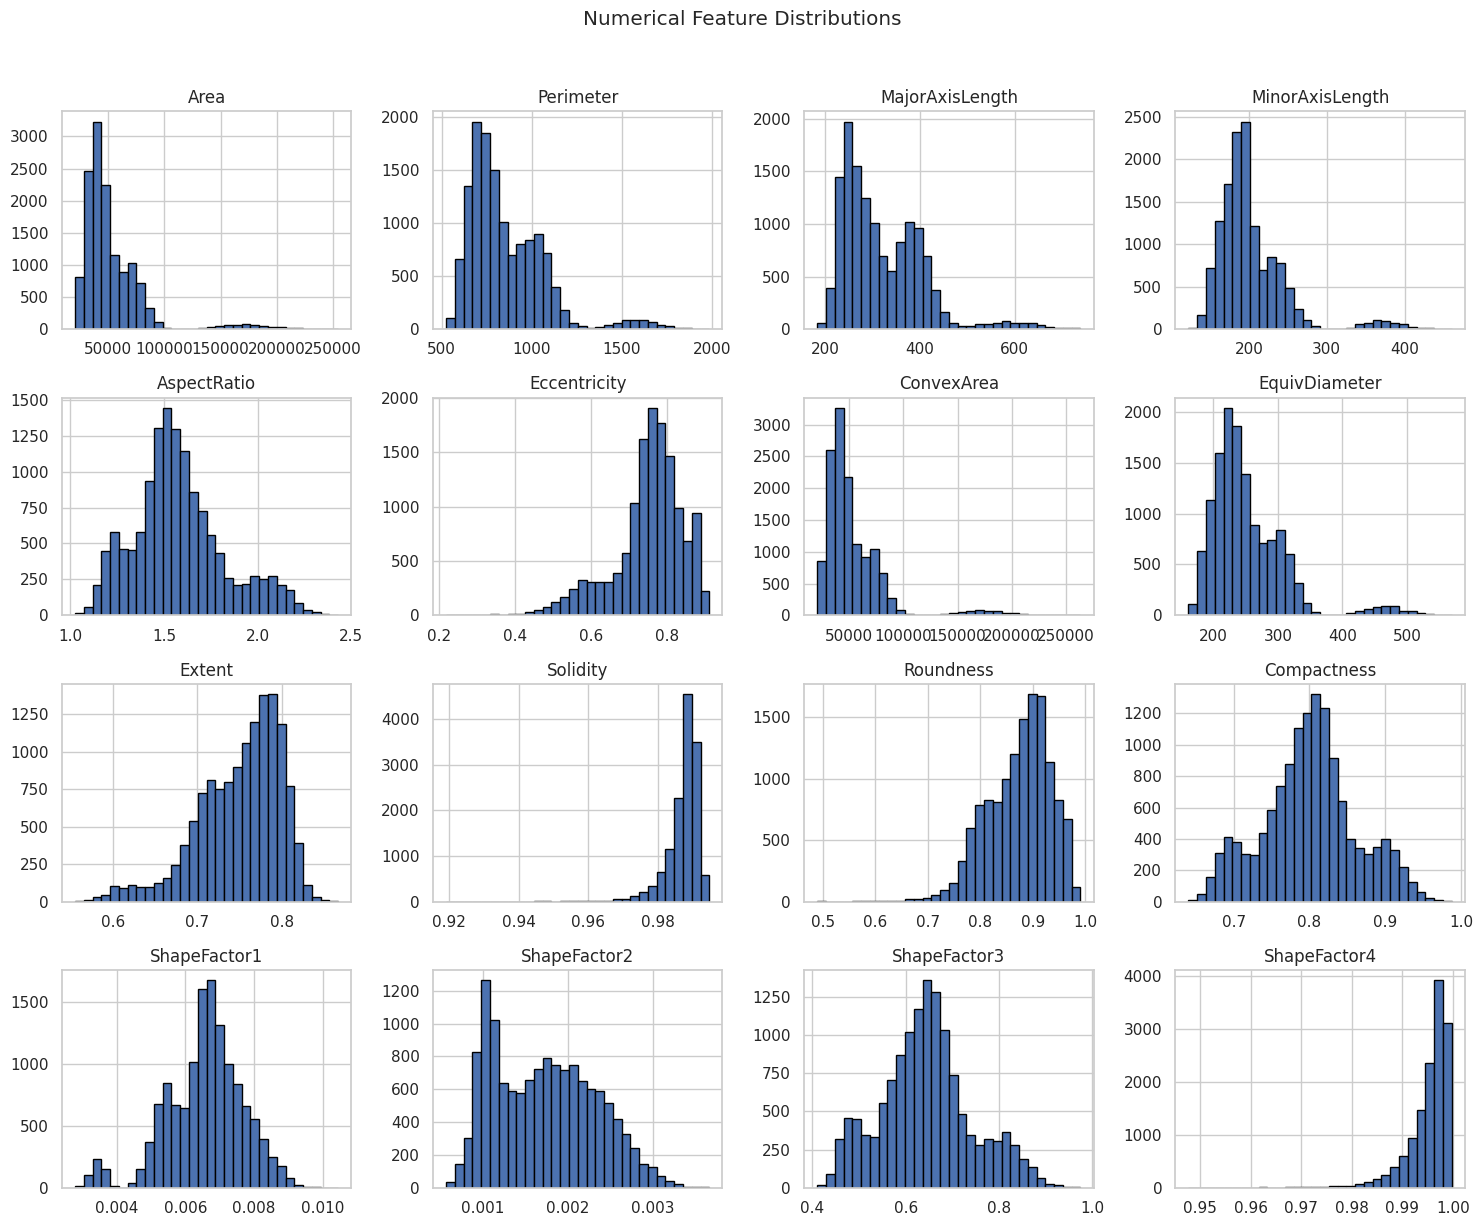

In [ ]:
df[numeric_features].hist(figsize=(15, 12), bins=30, edgecolor="black")
plt.suptitle("Numerical Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

### 4.3 Correlation heatmap

We use a correlation heatmap to see which features are strongly related and might contain similar information.


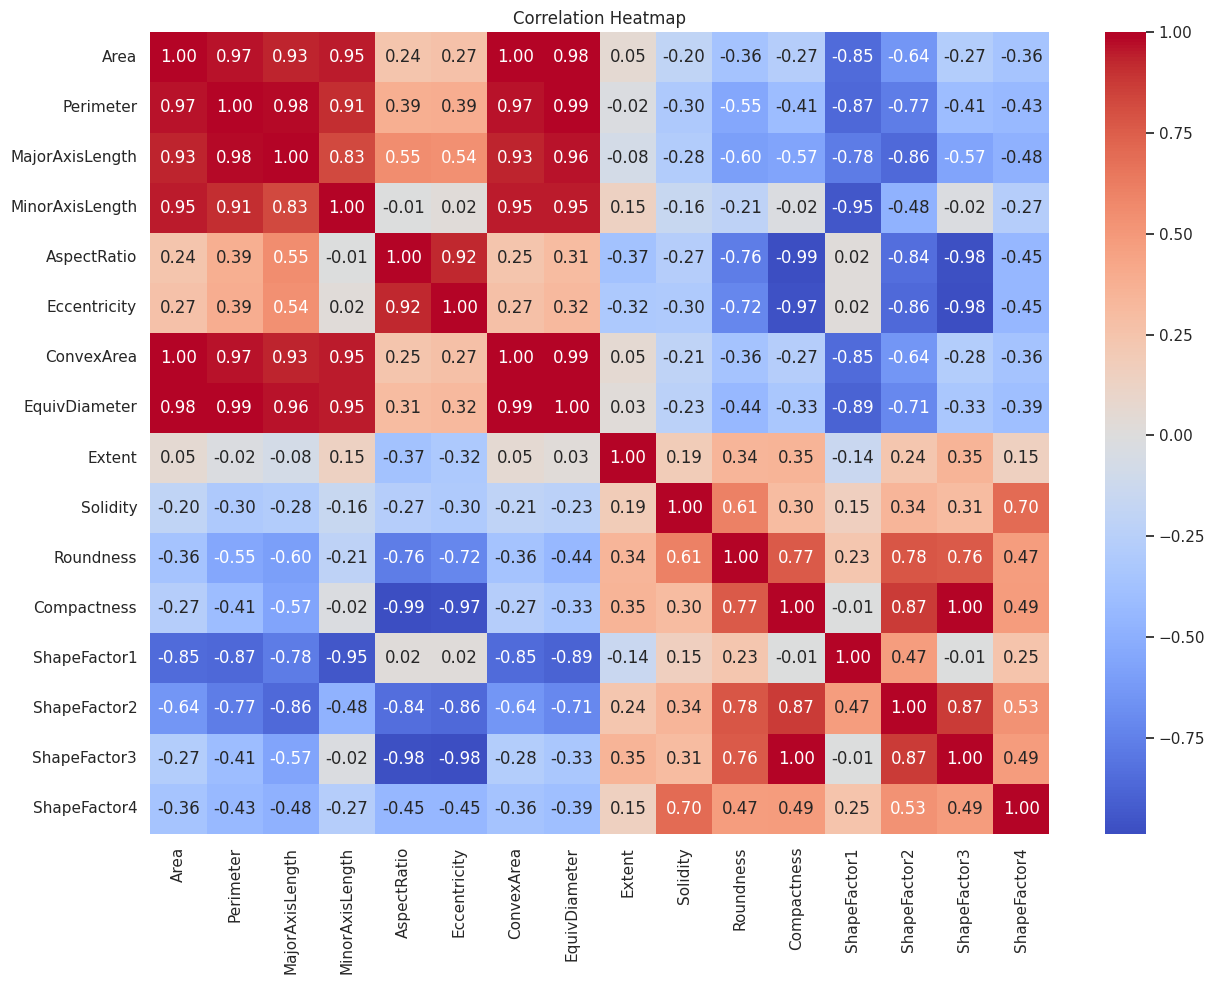

,Feature 1,Feature 2,Correlation,Absolute correlation
5,Area,ConvexArea,0.999940,0.999940
112,Compactness,ShapeFactor3,0.998684,0.998684
20,Perimeter,EquivDiameter,0.991453,0.991453
60,AspectRatio,Compactness,-0.987644,0.987644
75,ConvexArea,EquivDiameter,0.985255,0.985255
6,Area,EquivDiameter,0.984998,0.984998
73,Eccentricity,ShapeFactor3,-0.981058,0.981058
63,AspectRatio,ShapeFactor3,-0.978528,0.978528
15,Perimeter,MajorAxisLength,0.977561,0.977561
70,Eccentricity,Compactness,-0.970308,0.970308


In [ ]:
corr = df[numeric_features].corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong_pairs = upper.stack().rename("Correlation").reset_index()
strong_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]
strong_pairs["Absolute correlation"] = strong_pairs["Correlation"].abs()
display(strong_pairs.sort_values("Absolute correlation", ascending=False).head(10))

### 4.4 Relationships between features

The scatterplots help us see how selected measurements differ between the seven bean classes.


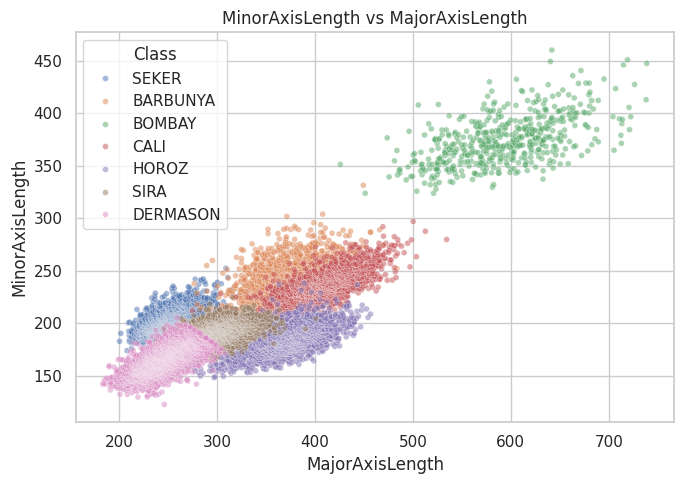

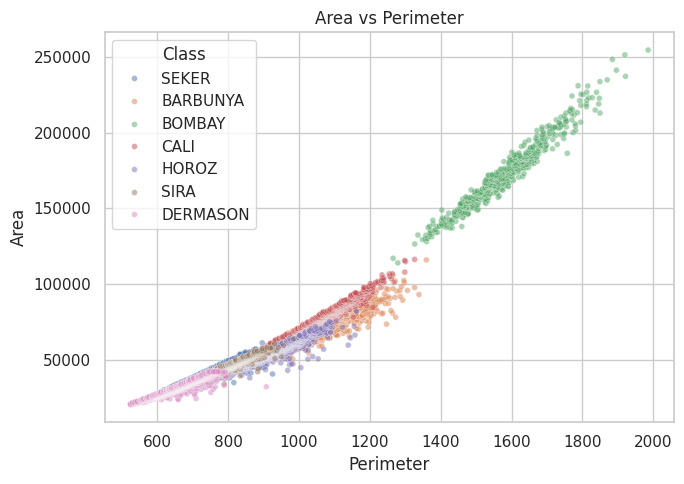

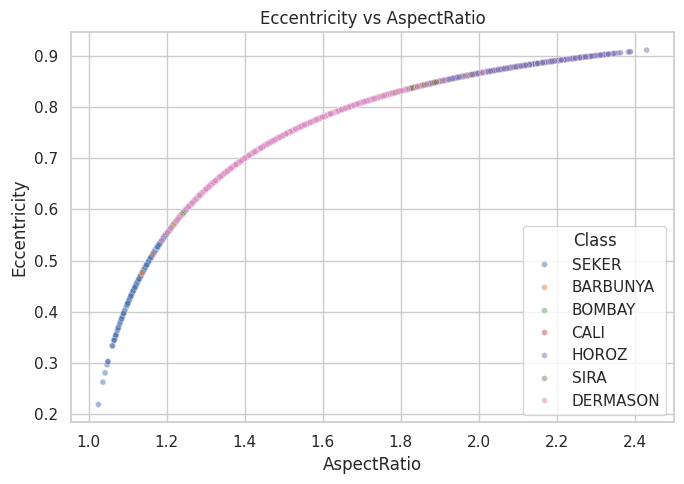

In [ ]:
pairs = [
    ("MajorAxisLength", "MinorAxisLength"),
    ("Perimeter", "Area"),
    ("AspectRatio", "Eccentricity")
]

for x_col, y_col in pairs:
    if x_col in df.columns and y_col in df.columns:
        plt.figure(figsize=(7, 5))
        sns.scatterplot(data=df, x=x_col, y=y_col, hue=target, alpha=0.5, s=18)
        plt.title(f"{y_col} vs {x_col}")
        plt.tight_layout()
        plt.show()

### 4.5 Comparing features across classes

We compare Area, MajorAxisLength, Compactness, and AspectRatio using boxplots.


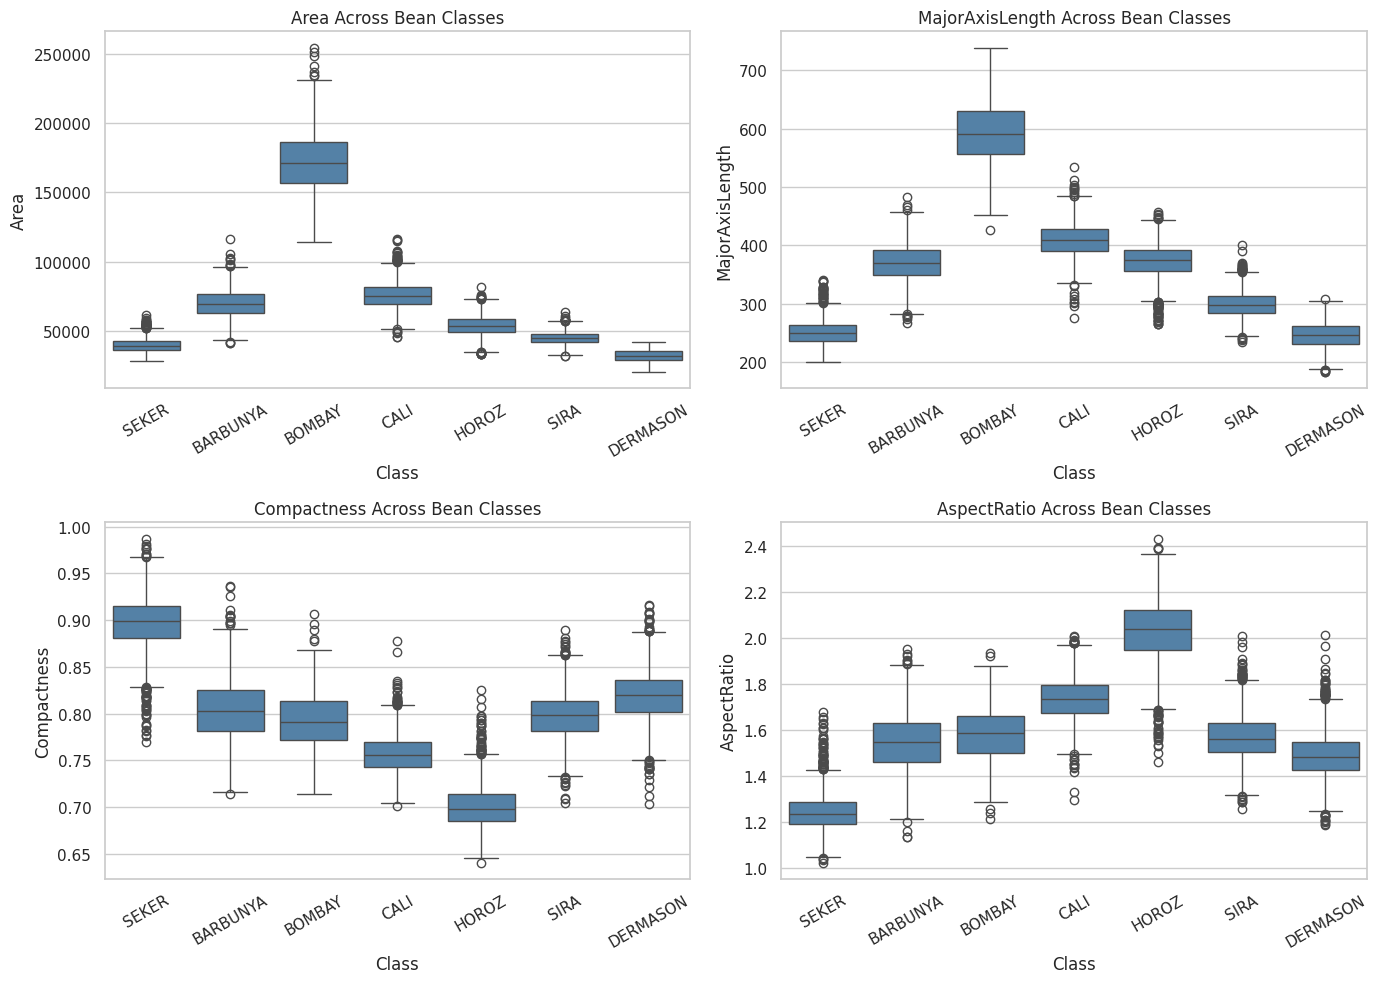

In [ ]:
selected = [
    c for c in ["Area", "MajorAxisLength", "Compactness", "AspectRatio"]
    if c in df.columns
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, selected):
    sns.boxplot(data=df, x=target, y=col, ax=ax, color="steelblue")
    ax.set_title(f"{col} Across Bean Classes")
    ax.tick_params(axis="x", rotation=30)

for ax in axes.flat[len(selected):]:
    ax.remove()

plt.tight_layout()
plt.show()

## Preparing the data and building the model

We will use the cleaned dataset for the next steps. To avoid data leakage, we will only use the training data when fitting preprocessing methods and selecting features.


In [ ]:
import os
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, classification_report, confusion_matrix)

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
INK, MUTED, BLUE, ORANGE = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": False,
                     "axes.edgecolor": "#c9c8c2", "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK})
from sklearn.base import BaseEstimator, TransformerMixin

SIZE_FEATURES = ["Area", "Perimeter", "MajorAxisLength", "MinorAxisLength", "ConvexArea", "EquivDiameter"]
LOG_FEATURES = ["log_" + c for c in SIZE_FEATURES]
RATIO_FEATURES = ["Ellipticity", "PerimeterToMajor"]

class BeanFeatureSelector(BaseEstimator, TransformerMixin):
    """Select features using the training data for each fold."""
    def __init__(self, mode="selected", threshold=0.95, random_state=42):
        self.mode = mode
        self.threshold = threshold
        self.random_state = random_state

    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()
        self.raw_features_ = list(X.columns)
        allowed = {"all", "selected", "all_log", "all_ratio", "selected_ratio", "selected_log"}
        if self.mode not in allowed:
            raise ValueError(f"Unknown mode {self.mode!r}")
        if self.mode.startswith("selected"):
            if y is None:
                raise ValueError("Selection requires y_train")
            scores = pd.Series(mutual_info_classif(X, y, random_state=self.random_state), index=X.columns)
            ranked = scores.sort_values(ascending=False, kind="stable").index
            corr = X.corr().abs()
            keep = []
            for feat in ranked:
                if not any(corr.loc[feat, chosen] > self.threshold for chosen in keep):
                    keep.append(feat)
            self.selected_original_ = keep
            self.relevance_scores_ = scores
        else:
            self.selected_original_ = list(X.columns)
        if self.mode == "all_log":
            self.output_features_ = self.raw_features_ + LOG_FEATURES
        elif self.mode == "all_ratio":
            self.output_features_ = self.raw_features_ + RATIO_FEATURES
        elif self.mode == "selected_ratio":
            self.output_features_ = self.selected_original_ + RATIO_FEATURES
        elif self.mode == "selected_log":
            self.output_features_ = ["log_" + c if c in SIZE_FEATURES else c for c in self.selected_original_]
        else:
            self.output_features_ = list(self.selected_original_)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        if self.mode in {"all_log", "all_ratio", "selected_ratio", "selected_log"}:
            if self.mode in {"all_log", "selected_log"}:
                for c in SIZE_FEATURES:
                    X["log_" + c] = np.log(X[c])
            if self.mode in {"all_ratio", "selected_ratio"}:
                X["Ellipticity"] = X["Area"] / (np.pi / 4 * X["MajorAxisLength"] * X["MinorAxisLength"])
                X["PerimeterToMajor"] = X["Perimeter"] / X["MajorAxisLength"]
        return X[self.output_features_].copy()

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.output_features_, dtype=object)

## 5. Data splitting

We split the cleaned data into **70% training, 15% validation, and 15% testing**. Since the dataset has seven classes with different numbers of records, we use stratified sampling to keep similar class proportions in each set. We also set `random_state=42` so the split can be reproduced.

The training set is used to fit the model, the validation set is used to check its performance, and the test set is saved for the final evaluation.


In [ ]:
X_all = df[features].copy()
y_all = df[target].astype(str).copy()

# Set aside the test set, then make the training and validation sets
X_temp, X_test_raw, y_temp, y_test_labels = train_test_split(
    X_all, y_all, test_size=0.15, stratify=y_all, random_state=RANDOM_STATE)
X_train_raw, X_val_raw, y_train_labels, y_val_labels = train_test_split(
    X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=RANDOM_STATE)

split_table = pd.DataFrame({
    "Train": y_train_labels.value_counts(),
    "Validation": y_val_labels.value_counts(),
    "Test": y_test_labels.value_counts()})
split_pct = (split_table / split_table.sum() * 100).round(2)
split_pct.columns = [c + " %" for c in split_pct.columns]
split_summary = pd.concat([split_table, split_pct], axis=1).sort_values("Train", ascending=False)
split_summary.loc["Total"] = [len(y_train_labels), len(y_val_labels), len(y_test_labels), 100, 100, 100]
display(split_summary)

# Check that the splits do not overlap
assert not set(X_train_raw.index) & set(X_val_raw.index)
assert not set(X_train_raw.index) & set(X_test_raw.index)
assert not set(X_val_raw.index) & set(X_test_raw.index)
assert len(X_train_raw) + len(X_val_raw) + len(X_test_raw) == len(df)
print("Train / Validation / Test:", len(X_train_raw), len(X_val_raw), len(X_test_raw))

,Train,Validation,Test,Train %,Validation %,Test %
Class,,,,,,
DERMASON,2482,532,532,26.18,26.18,26.18
SIRA,1844,396,396,19.45,19.49,19.49
SEKER,1419,304,304,14.97,14.96,14.96
HOROZ,1302,279,279,13.74,13.73,13.73
CALI,1140,245,245,12.03,12.06,12.06
BARBUNYA,926,198,198,9.77,9.74,9.74
BOMBAY,366,78,78,3.86,3.84,3.84
Total,9479,2032,2032,100.00,100.00,100.00


Train / Validation / Test: 9479 2032 2032


## 6. Target encoding

The class names are text labels, so we convert them into numbers from 0 to 6 using `LabelEncoder`. Each number represents one bean type; it does not mean that one class is higher or lower than another.


In [ ]:
label_encoder = LabelEncoder().fit(y_train_labels)
y_train = label_encoder.transform(y_train_labels)
y_val = label_encoder.transform(y_val_labels)
y_test = label_encoder.transform(y_test_labels)
class_names = list(label_encoder.classes_)
display(pd.DataFrame({"Class": class_names, "Encoded value": range(len(class_names))}))

,Class,Encoded value
0,BARBUNYA,0
1,BOMBAY,1
2,CALI,2
3,DERMASON,3
4,HOROZ,4
5,SEKER,5
6,SIRA,6


## 7. Feature relevance

We check which features are related to the target class using Mutual Information and the ANOVA F-score. These scores are calculated using the training data only.


,Mutual information,ANOVA F-score
Perimeter,1.058,17271.0
ConvexArea,1.040,20793.0
EquivDiameter,1.030,17922.0
Area,1.030,20803.0
MajorAxisLength,0.991,15210.0
ShapeFactor2,0.951,8579.0
ShapeFactor1,0.926,8394.0
MinorAxisLength,0.920,15742.0
Compactness,0.830,7018.0
ShapeFactor3,0.830,6837.0


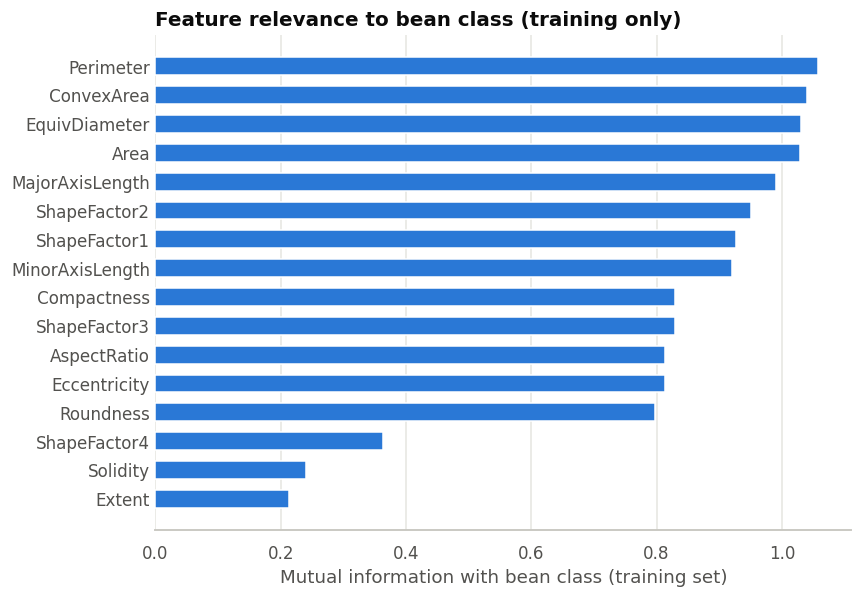

In [ ]:
mi_scores = pd.Series(mutual_info_classif(X_train_raw, y_train, random_state=RANDOM_STATE), index=features)
f_scores = pd.Series(f_classif(X_train_raw, y_train)[0], index=features)
relevance = pd.DataFrame({"Mutual information": mi_scores.round(3), "ANOVA F-score": f_scores.round(0)})
relevance = relevance.sort_values("Mutual information", ascending=False)
display(relevance)

order = relevance.index[::-1]
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.barh(order, mi_scores[order], color=BLUE, height=0.62)
ax.set_title("Feature relevance to bean class (training only)", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("Mutual information with bean class (training set)")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.xaxis.grid(True, color="#e6e5e0"); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("figures/fig6_feature_relevance.png"); plt.show()

## 8. Feature selection

Some measurements are highly correlated. We rank the features using Mutual Information and keep a feature only when its correlation with the ones already selected is not above **0.95**. For cross-validation, feature selection is repeated inside each training fold so the validation fold does not affect the selection.


In [ ]:
CORR_THRESHOLD = 0.95
selector_final = BeanFeatureSelector(mode="selected", threshold=CORR_THRESHOLD,
                                    random_state=RANDOM_STATE).fit(X_train_raw, y_train)
selected_features = list(selector_final.selected_original_)
train_corr = X_train_raw.corr().abs()
dropped_rows = []
for feat in relevance.index:
    if feat not in selected_features:
        kept_conflicts = [k for k in selected_features if train_corr.loc[feat, k] > CORR_THRESHOLD]
        if kept_conflicts:
            strongest = max(kept_conflicts, key=lambda k: train_corr.loc[feat, k])
            dropped_rows.append({"Dropped feature": feat, "Correlated with": strongest,
                                 "Absolute correlation": round(train_corr.loc[feat, strongest], 4)})
print(f"Kept {len(selected_features)} of {len(features)} features:", selected_features)
display(pd.DataFrame(dropped_rows))
print("Largest remaining absolute correlation:",
      round(train_corr.loc[selected_features, selected_features].where(
            ~np.eye(len(selected_features), dtype=bool)).max().max(), 4))
assert list(selector_final.transform(X_train_raw).columns) == selected_features

Kept 9 of 16 features: ['Perimeter', 'ShapeFactor2', 'ShapeFactor1', 'MinorAxisLength', 'ShapeFactor3', 'Roundness', 'ShapeFactor4', 'Solidity', 'Extent']


,Dropped feature,Correlated with,Absolute correlation
0,ConvexArea,Perimeter,0.9683
1,EquivDiameter,Perimeter,0.9917
2,Area,Perimeter,0.9673
3,MajorAxisLength,Perimeter,0.9779
4,Compactness,ShapeFactor3,0.9987
5,AspectRatio,ShapeFactor3,0.9785
6,Eccentricity,ShapeFactor3,0.9811


Largest remaining absolute correlation: 0.9469


## 9. Feature engineering experiments

We compare the original features, selected features, and some new features based on log transformations and ratios. We use **5-fold stratified cross-validation** on the training set. Feature selection and scaling are fitted separately in each fold to avoid data leakage.

We focus on Macro F1 because we want to consider all seven classes, including the smaller ones. If the new features give only a very small improvement, we will keep the simpler feature set.


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
modes = {
    "All 16 original features": "all",
    "Selected original features": "selected",
    "All + engineered ratios": "all_ratio",
    "Selected + engineered ratios": "selected_ratio",
    "Selected with log size features": "selected_log",
    "All + log size features": "all_log",
}
rows = []
for label, mode in modes.items():
    candidate_pipeline = Pipeline([
        ("select", BeanFeatureSelector(mode=mode, threshold=CORR_THRESHOLD, random_state=RANDOM_STATE)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000))
    ])
    scores = cross_validate(candidate_pipeline, X_train_raw, y_train,
                            cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=1)
    fitted_selector = BeanFeatureSelector(mode=mode, threshold=CORR_THRESHOLD,
                                         random_state=RANDOM_STATE).fit(X_train_raw, y_train)
    rows.append({"Feature set": label, "Features (full train)": len(fitted_selector.output_features_),
                 "CV accuracy": round(scores["test_accuracy"].mean(), 4),
                 "CV macro F1": round(scores["test_f1_macro"].mean(), 4),
                 "Macro F1 std": round(scores["test_f1_macro"].std(), 4)})
feature_set_results = pd.DataFrame(rows).sort_values("CV macro F1", ascending=False).reset_index(drop=True)
display(feature_set_results)
selected_cv_f1 = float(feature_set_results.loc[feature_set_results["Feature set"] == "Selected original features", "CV macro F1"].iloc[0])
engineering_gain = float(feature_set_results["CV macro F1"].max() - selected_cv_f1)
print(f"Best feature experiment macro F1 improvement vs selected baseline: {engineering_gain:.4f}")
print("Note: all feature-set experiments are training-only and do not evaluate the final test set.")
feature_set_results.to_csv("results/feature_set_cv_corrected.csv", index=False)

,Feature set,Features (full train),CV accuracy,CV macro F1,Macro F1 std
0,Selected + engineered ratios,11,0.9259,0.9386,0.0031
1,Selected with log size features,9,0.9257,0.9383,0.0034
2,All + engineered ratios,18,0.9256,0.9382,0.0039
3,Selected original features,9,0.9257,0.9382,0.0037
4,All 16 original features,16,0.9255,0.9381,0.0039
5,All + log size features,22,0.9250,0.9374,0.0042


Best feature experiment macro F1 improvement vs selected baseline: 0.0004
Note: all feature-set experiments are training-only and do not evaluate the final test set.


**Result:** The feature sets gave very similar cross-validation scores. We kept the nine selected original features because adding the engineered features did not give a clear improvement. The detailed scores are shown in the table above.


## 10. Feature scaling

The selected features have different scales, so we use `StandardScaler`. We fit it on the training data and apply the same transformation to the validation and test sets. The Logistic Regression pipeline below also includes its own scaler for cross-validation.


In [ ]:
X_train = X_train_raw[selected_features].copy()
X_val = X_val_raw[selected_features].copy()
X_test = X_test_raw[selected_features].copy()

scaler = StandardScaler().fit(X_train)
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=selected_features, index=X_train.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=selected_features, index=X_val.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=selected_features, index=X_test.index)

# Check scaling on the training and validation data
display(pd.DataFrame({"Train mean": X_train_scaled.mean().round(3),
                      "Train std": X_train_scaled.std().round(3),
                      "Validation mean": X_val_scaled.mean().round(3)}))
assert np.allclose(scaler.mean_, X_train.mean().values)
assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns) == selected_features
assert np.isfinite(X_train_scaled.values).all() and np.isfinite(X_val_scaled.values).all()

,Train mean,Train std,Validation mean
Perimeter,-0.0,1.0,-0.002
ShapeFactor2,-0.0,1.0,-0.005
ShapeFactor1,0.0,1.0,0.012
MinorAxisLength,0.0,1.0,-0.009
ShapeFactor3,-0.0,1.0,-0.012
Roundness,-0.0,1.0,-0.023
ShapeFactor4,0.0,1.0,-0.019
Solidity,-0.0,1.0,-0.022
Extent,-0.0,1.0,0.005


## 11. Logistic Regression

We use multiclass Logistic Regression as our first classification model. We apply `GridSearchCV` with five folds to find a suitable value for `C` and to check whether balanced class weights help.

The pipeline includes feature selection, scaling, and the model. This makes sure each step is learned from the training portion of every fold. We use Macro F1 to choose the best setting and then compare the training and validation results. We do not evaluate the test set yet.


,C,Class weight,Train macro F1,CV macro F1,CV std
6,1.0,None,0.9397,0.9382,0.0037
12,1000.0,None,0.9394,0.9381,0.0041
8,10.0,None,0.9395,0.9380,0.0048
10,100.0,None,0.9397,0.9378,0.0044
4,0.1,None,0.9386,0.9369,0.0041
11,100.0,balanced,0.9369,0.9358,0.0059


Best parameters: {'model__C': 1, 'model__class_weight': None}
Best estimator uses: ['Perimeter', 'ShapeFactor2', 'ShapeFactor1', 'MinorAxisLength', 'ShapeFactor3', 'Roundness', 'ShapeFactor4', 'Solidity', 'Extent']


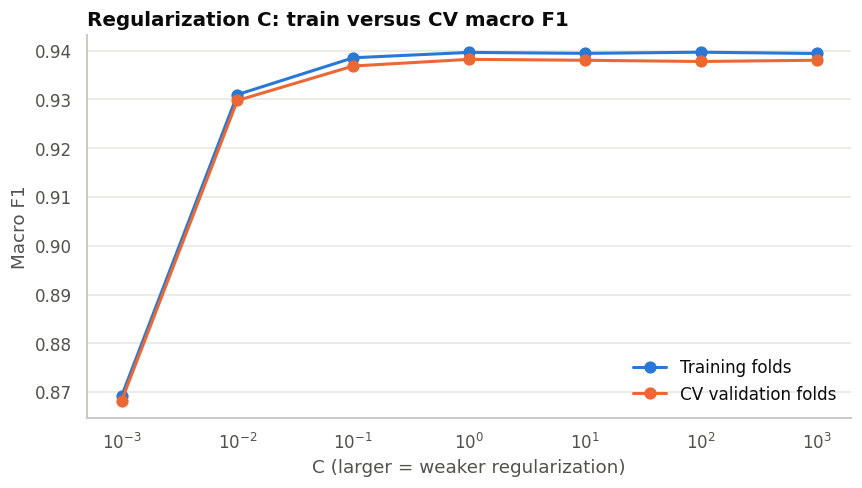

,Accuracy,Macro F1,Macro Precision,Macro Recall,ROC-AUC (OvR)
Set,,,,,
Training,0.9272,0.9397,0.9405,0.9391,0.9952
Validation,0.9227,0.9316,0.9317,0.9317,0.9943


Train minus validation macro F1: 0.0081


,precision,recall,f1-score,support
SIRA,0.8776,0.8687,0.8731,396
BARBUNYA,0.9119,0.8889,0.9003,198
DERMASON,0.9287,0.9305,0.9296,532
CALI,0.9240,0.9429,0.9333,245
HOROZ,0.9268,0.9534,0.9399,279
SEKER,0.9532,0.9375,0.9453,304
BOMBAY,1.0000,1.0000,1.0000,78


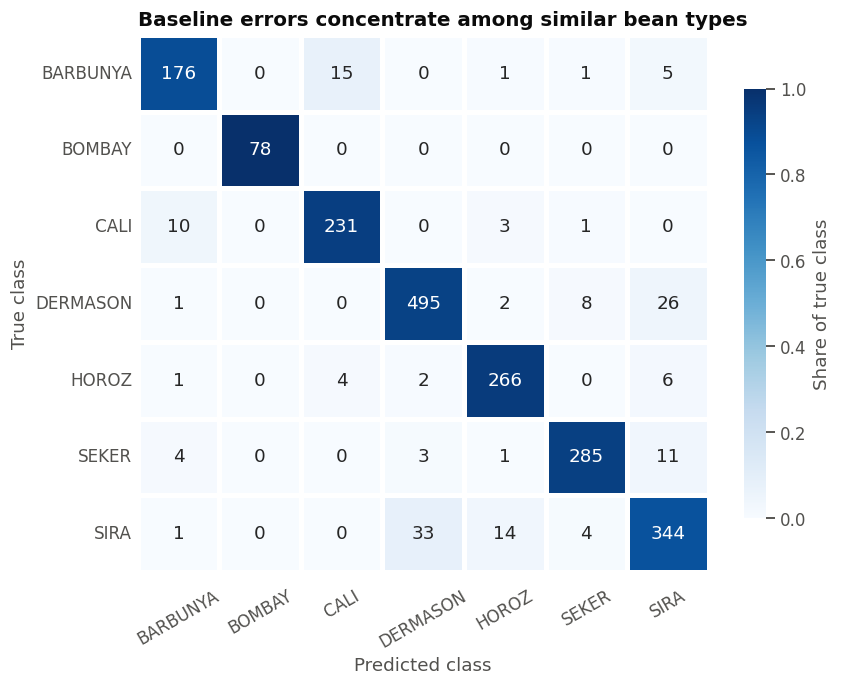

,True class,Predicted class,Count
45,SIRA,DERMASON,33
27,DERMASON,SIRA,26
2,BARBUNYA,CALI,15
46,SIRA,HOROZ,14
41,SEKER,SIRA,11
14,CALI,BARBUNYA,10


,Mean absolute coefficient
ShapeFactor1,2.379
MinorAxisLength,2.018
Perimeter,1.969
ShapeFactor2,1.763
ShapeFactor3,1.695
ShapeFactor4,1.326
Roundness,1.069
Solidity,0.449
Extent,0.304


In [ ]:
from joblib import Memory
# Reuse preprocessing results during the grid search to save time.

cv_cache = Memory(location="results/cv_pipeline_cache", verbose=0)
pipeline = Pipeline([
    ("select", BeanFeatureSelector(mode="selected", threshold=CORR_THRESHOLD, random_state=RANDOM_STATE)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
], memory=cv_cache)

param_grid = {"model__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000],
              "model__class_weight": [None, "balanced"]}
grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring="f1_macro",
                    return_train_score=True, n_jobs=1)
grid.fit(X_train_raw, y_train)  # no test or validation information; each fold refits selector AND scaler
cv_results = pd.DataFrame(grid.cv_results_)
tuning_table = cv_results[["param_model__C", "param_model__class_weight",
                           "mean_train_score", "mean_test_score", "std_test_score"]].copy()
tuning_table.columns = ["C", "Class weight", "Train macro F1", "CV macro F1", "CV std"]
tuning_table["Class weight"] = tuning_table["Class weight"].fillna("None")
display(tuning_table.round(4).sort_values("CV macro F1", ascending=False).head(6))
print("Best parameters:", grid.best_params_)
print("Best estimator uses:", grid.best_estimator_.named_steps["select"].output_features_)
tuning_table.to_csv("results/logistic_regression_cv_corrected.csv", index=False)

best_weight = grid.best_params_["model__class_weight"]
weights = cv_results["param_model__class_weight"]
weight_mask = weights.map(lambda w: w is None) if best_weight is None else weights.eq(best_weight)
curve = cv_results.loc[weight_mask].copy()
curve = curve.assign(C=curve["param_model__C"].astype(float)).sort_values("C")
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(curve["C"], curve["mean_train_score"], color=BLUE, lw=2, marker="o", ms=7, label="Training folds")
ax.plot(curve["C"], curve["mean_test_score"], color=ORANGE, lw=2, marker="o", ms=7, label="CV validation folds")
ax.set_xscale("log")
ax.set_title("Regularization C: train versus CV macro F1", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("C (larger = weaker regularization)")
ax.set_ylabel("Macro F1")
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#e6e5e0"); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig("figures/fig7_regularization_curve.png"); plt.show()
# Use the best fitted model
logreg = grid.best_estimator_
assert list(logreg.named_steps["select"].output_features_) == selected_features

def evaluate(model, X, y, split):
    pred, proba = model.predict(X), model.predict_proba(X)
    return {"Set": split, "Accuracy": accuracy_score(y, pred),
            "Macro F1": f1_score(y, pred, average="macro", zero_division=0),
            "Macro Precision": precision_score(y, pred, average="macro", zero_division=0),
            "Macro Recall": recall_score(y, pred, average="macro", zero_division=0),
            "ROC-AUC (OvR)": roc_auc_score(y, proba, multi_class="ovr", average="macro")}

# Pass the original input columns because the pipeline handles preprocessing
baseline_metrics = pd.DataFrame([evaluate(logreg, X_train_raw, y_train, "Training"),
                                 evaluate(logreg, X_val_raw, y_val, "Validation")]).set_index("Set")
display(baseline_metrics.round(4))
print("Train minus validation macro F1:",
      round(baseline_metrics.loc["Training", "Macro F1"] - baseline_metrics.loc["Validation", "Macro F1"], 4))
baseline_metrics.round(4).to_csv("results/logistic_regression_metrics.csv")

val_pred = logreg.predict(X_val_raw)
per_class = pd.DataFrame(classification_report(y_val, val_pred,
                         target_names=class_names, output_dict=True, zero_division=0)).T
per_class = per_class.loc[class_names].sort_values("f1-score")
per_class["support"] = per_class["support"].astype(int)
display(per_class.round(4))
cm = confusion_matrix(y_val, val_pred)
cm_share = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(8, 6.4))
sns.heatmap(cm_share, annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1, linewidths=2, linecolor="white",
            xticklabels=class_names, yticklabels=class_names, ax=ax,
            cbar_kws={"label": "Share of true class", "shrink": 0.8})
ax.set_title("Baseline errors concentrate among similar bean types", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.tick_params(axis="x", rotation=30); ax.tick_params(axis="y", rotation=0, length=0)
plt.tight_layout(); plt.savefig("figures/fig8_confusion_matrix.png"); plt.show()

confusions = pd.DataFrame(cm, index=class_names, columns=class_names).stack().rename("Count").reset_index()
confusions.columns = ["True class", "Predicted class", "Count"]
display(confusions[confusions["True class"] != confusions["Predicted class"]].sort_values("Count", ascending=False).head(6))

coefficients = pd.DataFrame(logreg.named_steps["model"].coef_, index=class_names, columns=selected_features)
importance = coefficients.abs().mean().sort_values(ascending=False).rename("Mean absolute coefficient").to_frame()
display(importance.round(3))

**Results:** The tables above show the training and validation scores, as well as the results for each class. We also use the confusion matrix to see which bean types are most often mixed up. The training and validation results are close, which is a good sign, although it does not guarantee that the model has no overfitting.


In [ ]:
per_class.round(4).to_csv("results/logistic_regression_validation_per_class.csv")
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv("results/logistic_regression_validation_confusion_matrix.csv")
print("Saved training and validation results.")

Saved training and validation results.


## 12. Random Forest baseline

Random Forest is an ensemble of decision trees that can learn non-linear patterns in the bean measurements. We first train a baseline model on the training set and check its performance on the validation set. Macro F1 is used as the main score because the seven classes have different numbers of records.


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

rf_baseline = Pipeline([
    ("select", BeanFeatureSelector(mode="selected", threshold=CORR_THRESHOLD,
                                   random_state=RANDOM_STATE)),
    ("model", RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE,
                                     n_jobs=-1))
])
rf_baseline.fit(X_train_raw, y_train)

rf_baseline_metrics = pd.DataFrame([
    evaluate(rf_baseline, X_train_raw, y_train, "Training"),
    evaluate(rf_baseline, X_val_raw, y_val, "Validation")
]).set_index("Set")
display(rf_baseline_metrics.round(4))
print("Baseline validation macro F1:", round(rf_baseline_metrics.loc["Validation", "Macro F1"], 4))

,Accuracy,Macro F1,Macro Precision,Macro Recall,ROC-AUC (OvR)
Set,,,,,
Training,1.0000,1.000,1.0000,1.0000,1.0000
Validation,0.9203,0.931,0.9321,0.9303,0.9945


Baseline validation macro F1: 0.931


## 13. Random Forest hyperparameter tuning

We use `RandomizedSearchCV` with stratified cross-validation to try different numbers of trees, tree depths, and minimum samples per split or leaf. The feature selector is fitted again within each training fold, and the best settings are chosen using Macro F1. The test set is not used during tuning.


In [ ]:
rf_pipeline = Pipeline([
    ("select", BeanFeatureSelector(mode="selected", threshold=CORR_THRESHOLD,
                                   random_state=RANDOM_STATE)),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))
])
rf_param_distributions = {
    "model__n_estimators": [120, 180, 250],
    "model__max_depth": [None, 12, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7],
    "model__class_weight": [None, "balanced"]
}
rf_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=10,
    scoring="f1_macro",
    cv=rf_cv,
    n_jobs=2,
    random_state=RANDOM_STATE,
    return_train_score=True,
    verbose=1
)
rf_search.fit(X_train_raw, y_train)
rf_best_model = rf_search.best_estimator_

print("Best RF hyperparameters:", rf_search.best_params_)
print("Best training-only CV Macro F1:", round(rf_search.best_score_, 4))
print("Final selected RF input features:",
      list(rf_best_model.named_steps["select"].output_features_))

rf_cv_results = pd.DataFrame(rf_search.cv_results_)
rf_tuning_table = rf_cv_results[["params", "mean_train_score", "mean_test_score", "std_test_score"]].copy()
rf_tuning_table.columns = ["Hyperparameters", "Train Macro F1", "CV Macro F1", "CV Std"]
rf_tuning_table = rf_tuning_table.sort_values("CV Macro F1", ascending=False)
display(rf_tuning_table.head(10).round(4))
rf_tuning_table.to_csv("results/random_forest_cv_tuning.csv", index=False)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best RF hyperparameters: {'model__n_estimators': 250, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 12, 'model__class_weight': 'balanced'}
Best training-only CV Macro F1: 0.9376
Final selected RF input features: ['Perimeter', 'ShapeFactor2', 'ShapeFactor1', 'MinorAxisLength', 'ShapeFactor3', 'Roundness', 'ShapeFactor4', 'Solidity', 'Extent']


,Hyperparameters,Train Macro F1,CV Macro F1,CV Std
5,"{'model__n_estimators': 250, 'model__min_sampl...",0.9844,0.9376,0.0029
4,"{'model__n_estimators': 250, 'model__min_sampl...",0.9881,0.9367,0.0020
9,"{'model__n_estimators': 180, 'model__min_sampl...",0.9879,0.9363,0.0026
1,"{'model__n_estimators': 120, 'model__min_sampl...",0.9700,0.9358,0.0027
3,"{'model__n_estimators': 120, 'model__min_sampl...",0.9967,0.9355,0.0032
7,"{'model__n_estimators': 180, 'model__min_sampl...",0.9745,0.9355,0.0030
8,"{'model__n_estimators': 120, 'model__min_sampl...",0.9838,0.9354,0.0034
2,"{'model__n_estimators': 120, 'model__min_sampl...",0.9722,0.9349,0.0036
6,"{'model__n_estimators': 120, 'model__min_sampl...",0.9917,0.9349,0.0023
0,"{'model__n_estimators': 180, 'model__min_sampl...",0.9739,0.9347,0.0031


## 14. Training and validation performance

We compare the tuned Random Forest with the baseline model to see whether tuning helped. We also compare training and validation scores to check for possible overfitting.


,Accuracy,Macro F1,Macro Precision,Macro Recall,ROC-AUC (OvR)
Set,,,,,
Training,0.9754,0.9810,0.9816,0.9804,0.9993
Validation,0.9218,0.9327,0.9330,0.9326,0.9954


Tuned RF train minus validation Macro F1: 0.0483
RF validation Macro F1 before tuning: 0.931
RF validation Macro F1 after tuning: 0.9327


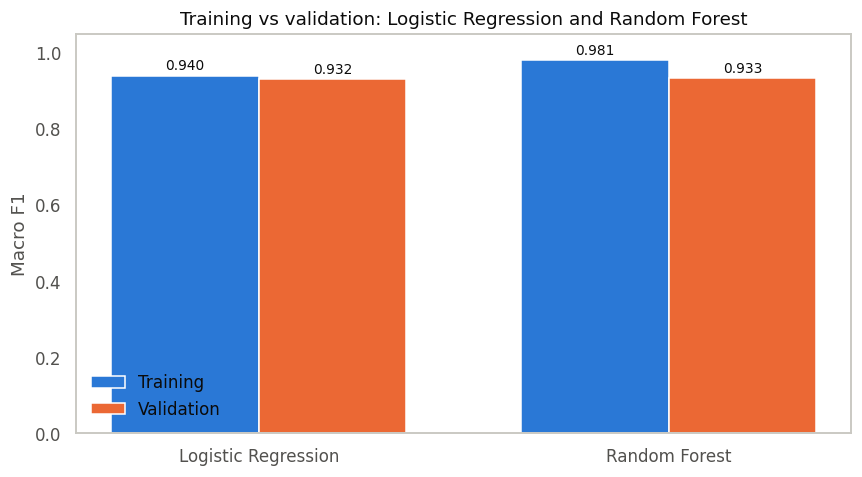

In [ ]:
rf_metrics = pd.DataFrame([
    evaluate(rf_best_model, X_train_raw, y_train, "Training"),
    evaluate(rf_best_model, X_val_raw, y_val, "Validation")
]).set_index("Set")
display(rf_metrics.round(4))

rf_gap = rf_metrics.loc["Training", "Macro F1"] - rf_metrics.loc["Validation", "Macro F1"]
print("Tuned RF train minus validation Macro F1:", round(rf_gap, 4))
print("RF validation Macro F1 before tuning:",
      round(rf_baseline_metrics.loc["Validation", "Macro F1"], 4))
print("RF validation Macro F1 after tuning:",
      round(rf_metrics.loc["Validation", "Macro F1"], 4))
rf_metrics.to_csv("results/random_forest_training_validation_metrics.csv")

models_for_plot = ["Logistic Regression", "Random Forest"]
train_f1s = [baseline_metrics.loc["Training", "Macro F1"], rf_metrics.loc["Training", "Macro F1"]]
val_f1s = [baseline_metrics.loc["Validation", "Macro F1"], rf_metrics.loc["Validation", "Macro F1"]]
x = np.arange(len(models_for_plot))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - 0.18, train_f1s, width=0.36, label="Training", color=BLUE)
ax.bar(x + 0.18, val_f1s, width=0.36, label="Validation", color=ORANGE)
ax.set_xticks(x, models_for_plot)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Macro F1")
ax.set_title("Training vs validation: Logistic Regression and Random Forest")
ax.legend(frameon=False)
for i, scores in enumerate([train_f1s, val_f1s]):
    for j, score in enumerate(scores):
        ax.text(j + (-0.18 if i == 0 else 0.18), score + 0.015,
                f"{score:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("figures/fig9_rf_train_validation_comparison.png")
plt.show()

## 15. Confusion matrix and feature importance

The confusion matrix shows which bean classes are predicted correctly and which are confused with each other. Feature importance helps us see which measurements the Random Forest uses most in its predictions.


,precision,recall,f1-score,support
BARBUNYA,0.9231,0.9091,0.9160,198.0
BOMBAY,1.0000,1.0000,1.0000,78.0
CALI,0.9317,0.9469,0.9393,245.0
DERMASON,0.9099,0.9305,0.9201,532.0
HOROZ,0.9293,0.9427,0.9359,279.0
SEKER,0.9507,0.9507,0.9507,304.0
SIRA,0.8865,0.8485,0.8671,396.0


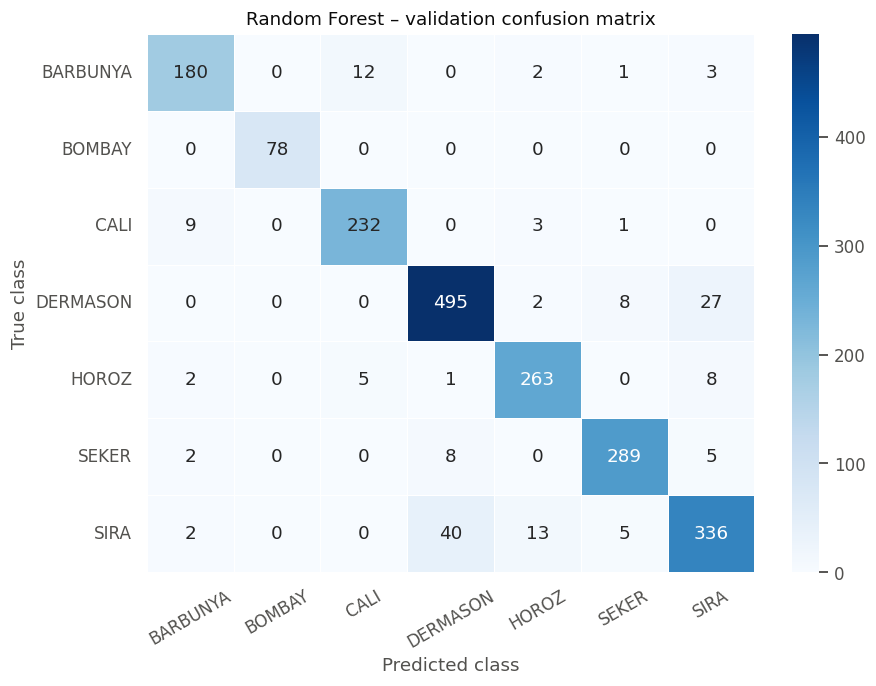

,Random Forest importance
ShapeFactor1,0.1901
ShapeFactor3,0.1896
Perimeter,0.1669
MinorAxisLength,0.1601
ShapeFactor2,0.1107
Roundness,0.1016
ShapeFactor4,0.0485
Solidity,0.0232
Extent,0.0094


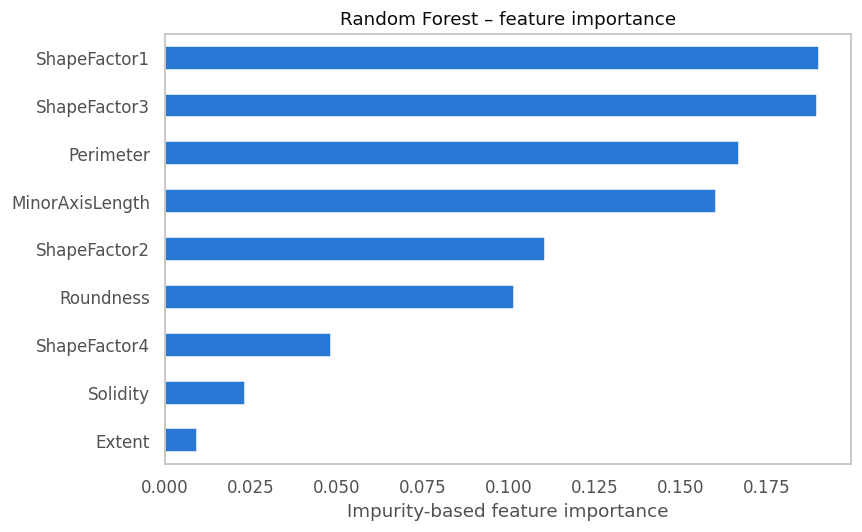

In [ ]:
rf_val_pred = rf_best_model.predict(X_val_raw)
rf_class_report = pd.DataFrame(classification_report(
    y_val, rf_val_pred, target_names=class_names, output_dict=True, zero_division=0
)).T
rf_class_report = rf_class_report.loc[class_names]
display(rf_class_report.round(4))
rf_class_report.to_csv("results/random_forest_validation_per_class.csv")

rf_cm = confusion_matrix(y_val, rf_val_pred)
fig, ax = plt.subplots(figsize=(8.5, 6.4))
sns.heatmap(rf_cm, annot=True, fmt="d", cmap="Blues", linewidths=.4,
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_title("Random Forest – validation confusion matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("figures/fig10_rf_validation_confusion_matrix.png")
plt.show()
pd.DataFrame(rf_cm, index=class_names, columns=class_names).to_csv(
    "results/random_forest_validation_confusion_matrix.csv")

rf_used_features = list(rf_best_model.named_steps["select"].output_features_)
rf_feature_importance = pd.Series(
    rf_best_model.named_steps["model"].feature_importances_,
    index=rf_used_features,
    name="Random Forest importance"
).sort_values(ascending=False)
display(rf_feature_importance.to_frame().round(4))
rf_feature_importance.to_csv("results/random_forest_feature_importance.csv")
fig, ax = plt.subplots(figsize=(8, 5))
rf_feature_importance.sort_values().plot.barh(ax=ax, color=BLUE)
ax.set_title("Random Forest – feature importance")
ax.set_xlabel("Impurity-based feature importance")
plt.tight_layout()
plt.savefig("figures/fig11_rf_feature_importance.png")
plt.show()

## 16. Model comparison on the validation set

We compare Logistic Regression and Random Forest using the same validation data and evaluation metrics. After training the Neural Network, the three final models will be evaluated on the reserved test set.


In [ ]:
compare_columns = ["Accuracy", "Macro F1", "Macro Precision", "Macro Recall", "ROC-AUC (OvR)"]
validation_comparison = pd.DataFrame([
    {"Model": "Logistic Regression", **baseline_metrics.loc["Validation", compare_columns].to_dict()},
    {"Model": "Random Forest", **rf_metrics.loc["Validation", compare_columns].to_dict()}
]).set_index("Model")
display(validation_comparison.round(4))
validation_comparison.to_csv("results/traditional_models_validation_comparison.csv")
print("Traditional model validation comparison saved.")

,Accuracy,Macro F1,Macro Precision,Macro Recall,ROC-AUC (OvR)
Model,,,,,
Logistic Regression,0.9227,0.9316,0.9317,0.9317,0.9943
Random Forest,0.9218,0.9327,0.9330,0.9326,0.9954


Traditional model validation comparison saved.


## 17. Deep Learning (MLP)
In this section, an MLP neural network was developed to classify the seven Dry Bean varieties. The model was trained and evaluated, and hyperparameter tuning was performed to improve its performance. Its results were then compared with the traditional machine learning models.

### 17.1 PyTorch Setup

PyTorch was used to build and train the MLP model. The required libraries were imported, and the device (GPU or CPU) was selected for training. The random seed was also set to ensure reproducible results.

In [ ]:
# Import PyTorch
import copy
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

In [ ]:
# Reproducibility
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Using device:", device)

PyTorch version: 2.14.1+cu130
Using device: cuda


In [ ]:
# Check existing prepared data
print("\nData shapes:")
print("X_train:", X_train_scaled.shape)
print("X_val:", X_val_scaled.shape)
print("X_test:", X_test_scaled.shape)

print("\nNumber of classes:", len(class_names))
print("Number of selected features:", len(selected_features))


Data shapes:
X_train: (9479, 9)
X_val: (2032, 9)
X_test: (2032, 9)

Number of classes: 7
Number of selected features: 9


### 17.2 Data Conversion to PyTorch Tensors
The prepared training and validation data were converted into PyTorch tensors so they could be used as input to the MLP model. The input features and target labels were converted into the appropriate tensor formats.

In [ ]:
# Convert existing data into PyTorch tensors

X_train_tensor = torch.tensor(X_train_scaled.to_numpy(dtype=np.float32))
X_val_tensor = torch.tensor(X_val_scaled.to_numpy(dtype=np.float32))
X_test_tensor = torch.tensor(X_test_scaled.to_numpy(dtype=np.float32))

y_train_tensor = torch.tensor(np.asarray(y_train), dtype=torch.long)
y_val_tensor = torch.tensor(np.asarray(y_val), dtype=torch.long)
y_test_tensor = torch.tensor(np.asarray(y_test), dtype=torch.long)

print("Training:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation:", X_val_tensor.shape, y_val_tensor.shape)
print("Testing:", X_test_tensor.shape, y_test_tensor.shape)

Training: torch.Size([9479, 9]) torch.Size([9479])
Validation: torch.Size([2032, 9]) torch.Size([2032])
Testing: torch.Size([2032, 9]) torch.Size([2032])


In [ ]:
# Datasets (the DataLoaders are created inside the training function)
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

### 17.3 Build the MLP Architecture

The MLP class is flexible: each hidden layer is a fully connected layer followed by batch normalization, ReLU activation, and dropout, and the output layer has seven units (one per bean class). Its default settings (three hidden layers with 128, 64, and 32 neurons and dropout of 0.25) are the baseline architecture. The number and size of the hidden layers and the dropout rate are tuned in Section 17.6; the final model uses two hidden layers (64 and 32 neurons) without dropout.

In [ ]:
class MLPClassifier(nn.Module):

    def __init__(self, input_size, num_classes, hidden_sizes=(128, 64, 32), dropout=0.25):
        super().__init__()

        layers = []
        previous_size = input_size

        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(nn.BatchNorm1d(hidden_size))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            previous_size = hidden_size

        layers.append(nn.Linear(previous_size, num_classes))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


In [ ]:
# Default architecture, only to inspect it (not used later)
model_demo = MLPClassifier(
    input_size=X_train_tensor.shape[1],
    num_classes=len(class_names)
).to(device)

print(model_demo)

print("\nTrainable parameters:",
      sum(p.numel() for p in model_demo.parameters() if p.requires_grad))

MLPClassifier(
  (network): Sequential(
    (0): Linear(in_features=9, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.25, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.25, inplace=False)
    (12): Linear(in_features=32, out_features=7, bias=True)
  )
)

Trainable parameters: 12295


### 17.4 Training & Prediction Function

This section defines the functions used to train the MLP model, make predictions, and evaluate its performance. The training process uses AdamW optimizer and a learning rate scheduler to improve training stability. Early stopping is applied to prevent overfitting by monitoring the validation loss and saving the best model. The prediction function returns class probabilities using Softmax, while the evaluation function calculates Accuracy, Macro Precision, Macro Recall, Macro F1, and ROC-AUC to compare the MLP with the other models.

In [ ]:
def train_mlp(config, seed=RANDOM_STATE, epochs=100, patience=12, verbose=False):
    """Train one MLP and return the best model (by validation loss) and its history."""

    # Reproducibility for this run
    torch.manual_seed(seed)
    np.random.seed(seed)
    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=config["batch_size"],
        shuffle=True,
        generator=generator,
        drop_last=False
    )
    val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)

    run_model = MLPClassifier(
        input_size=X_train_tensor.shape[1],
        num_classes=len(class_names),
        hidden_sizes=config["hidden_sizes"],
        dropout=config["dropout"]
    ).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        run_model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"]
    )
    # Reduce the learning rate when the validation loss stops improving
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=5
    )

    best_val_loss = float("inf")
    best_epoch = 0
    patience_counter = 0
    best_model_state = None
    train_losses, val_losses = [], []

    for epoch in range(epochs):

        # Training
        run_model.train()
        running_train_loss = 0.0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            outputs = run_model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

            running_train_loss += loss.item() * X_batch.size(0)

        epoch_train_loss = running_train_loss / len(train_dataset)

        # Validation
        run_model.eval()
        running_val_loss = 0.0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                outputs = run_model(X_batch)
                loss = criterion(outputs, y_batch)
                running_val_loss += loss.item() * X_batch.size(0)

        epoch_val_loss = running_val_loss / len(val_dataset)

        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)
        scheduler.step(epoch_val_loss)

        # Early stopping based on validation loss
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_epoch = epoch + 1
            patience_counter = 0
            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in run_model.state_dict().items()
            }
        else:
            patience_counter += 1

        if verbose:
            print(
                f"Epoch {epoch + 1}/{epochs} "
                f"- Train Loss: {epoch_train_loss:.4f} "
                f"- Validation Loss: {epoch_val_loss:.4f} "
                f"- LR: {optimizer.param_groups[0]['lr']:.6f}"
            )

        if patience_counter >= patience:
            if verbose:
                print(f"Early stopping at epoch {epoch + 1}")
            break

    # Restore the best model
    run_model.load_state_dict(best_model_state)
    run_model.eval()

    return {
        "model": run_model,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss
    }

In [ ]:
def predict_probs(model, X_tensor):
    """Return softmax probabilities as a NumPy array."""
    model.eval()
    with torch.no_grad():
        outputs = model(X_tensor.to(device))
        probabilities = torch.softmax(outputs, dim=1)
    return probabilities.cpu().numpy()

In [ ]:
def mlp_metrics(y_true, probs):
    """Same metrics used for Logistic Regression and Random Forest."""
    pred = probs.argmax(axis=1)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Macro Precision": precision_score(y_true, pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, pred, average="macro", zero_division=0),
        "ROC-AUC (OvR)": roc_auc_score(y_true, probs, multi_class="ovr", average="macro")
    }

### 17.5 Baseline MLP

The baseline MLP is trained using the initial settings. It has three hidden layers with 128, 64, and 32 neurons. The model is evaluated on the training and validation sets, and its results are saved for comparison with later experiments.

In [ ]:
# Baseline MLP: the original settings
baseline_config = {"hidden_sizes": (128, 64, 32), "dropout": 0.25,
                   "lr": 0.001, "weight_decay": 0.0001, "batch_size": 128}

baseline_run = train_mlp(baseline_config, seed=RANDOM_STATE)
baseline_model = baseline_run["model"]

mlp_baseline_metrics = pd.DataFrame([
    {"Set": "Training", **mlp_metrics(y_train, predict_probs(baseline_model, X_train_tensor))},
    {"Set": "Validation", **mlp_metrics(y_val, predict_probs(baseline_model, X_val_tensor))}
]).set_index("Set")
display(mlp_baseline_metrics.round(4))

print("Baseline best epoch:", baseline_run["best_epoch"])
mlp_baseline_metrics.round(4).to_csv("results/mlp_baseline_metrics.csv")

,Accuracy,Macro Precision,Macro Recall,Macro F1,ROC-AUC (OvR)
Set,,,,,
Training,0.9353,0.9479,0.9458,0.9468,0.9962
Validation,0.9286,0.9390,0.9390,0.9389,0.9955


Baseline best epoch: 16


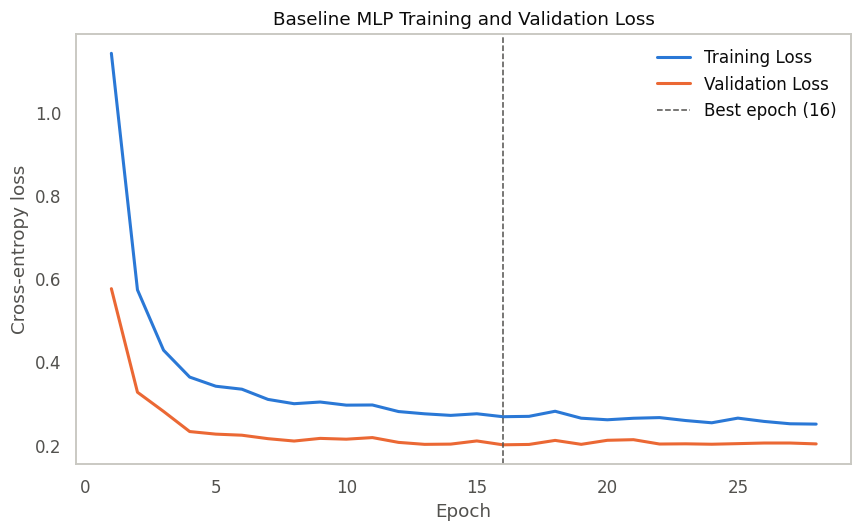

In [ ]:
# Learning curves for the baseline MLP
train_l = baseline_run["train_losses"]
val_l = baseline_run["val_losses"]
best = baseline_run["best_epoch"]

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_l) + 1), train_l, color=BLUE, lw=2, label="Training Loss")
plt.plot(range(1, len(val_l) + 1), val_l, color=ORANGE, lw=2, label="Validation Loss")
plt.axvline(best, color=MUTED, linestyle="--", lw=1, label=f"Best epoch ({best})")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Baseline MLP Training and Validation Loss")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("figures/fig_mlp_baseline_learning_curves.png")
plt.show()

### 17.6 Hyperparameter Tuning

In this step, different MLP settings are tested to find the best combination of hyperparameters. These include the number of hidden layers, dropout, learning rate, weight decay, and batch size. Each configuration is evaluated using the validation set, and the results are sorted based on Macro F1 to select the best configuration.

In [42]:
from sklearn.model_selection import ParameterGrid

mlp_param_grid = {
    "hidden_sizes": [(64, 32), (128, 64, 32), (256, 128, 64)],
    "dropout": [0.0, 0.1, 0.25],
    "lr": [0.001, 0.003],
    "weight_decay": [0.0001, 0.001],
    "batch_size": [64, 128]
}

search_configs = list(ParameterGrid(mlp_param_grid))
N_CONFIGS = len(search_configs)
print(f"Number of configurations: {N_CONFIGS}\n{'-' * 50}")

tuning_rows = []
for i, config in enumerate(search_configs, start=1):
    result = train_mlp(config, seed=RANDOM_STATE)
    val_scores = mlp_metrics(y_val, predict_probs(result["model"], X_val_tensor))

    tuning_rows.append({
        "Hidden sizes": str(config["hidden_sizes"]),
        "Dropout": config["dropout"],
        "LR": config["lr"],
        "Weight decay": config["weight_decay"],
        "Batch size": config["batch_size"],
        "Best epoch": result["best_epoch"],
        "Val loss": round(result["best_val_loss"], 4),
        "Val Macro F1": round(val_scores["Macro F1"], 4),
        "config": config
    })
    print(f"Config {i}/{N_CONFIGS} done - Val Macro F1: {val_scores['Macro F1']:.4f}")

mlp_tuning_table = pd.DataFrame(tuning_rows).sort_values(
    ["Val Macro F1", "Val loss"], ascending=[False, True]
).reset_index(drop=True)

Number of configurations: 72
--------------------------------------------------
Config 1/72 done - Val Macro F1: 0.9413
Config 2/72 done - Val Macro F1: 0.9429
Config 3/72 done - Val Macro F1: 0.9432
Config 4/72 done - Val Macro F1: 0.9419
Config 5/72 done - Val Macro F1: 0.9410
Config 6/72 done - Val Macro F1: 0.9405
Config 7/72 done - Val Macro F1: 0.9389
Config 8/72 done - Val Macro F1: 0.9345
Config 9/72 done - Val Macro F1: 0.9387
Config 10/72 done - Val Macro F1: 0.9354
Config 11/72 done - Val Macro F1: 0.9409
Config 12/72 done - Val Macro F1: 0.9407
Config 13/72 done - Val Macro F1: 0.9397
Config 14/72 done - Val Macro F1: 0.9395
Config 15/72 done - Val Macro F1: 0.9402
Config 16/72 done - Val Macro F1: 0.9424
Config 17/72 done - Val Macro F1: 0.9381
Config 18/72 done - Val Macro F1: 0.9377
Config 19/72 done - Val Macro F1: 0.9405
Config 20/72 done - Val Macro F1: 0.9405
Config 21/72 done - Val Macro F1: 0.9407
Config 22/72 done - Val Macro F1: 0.9415
Config 23/72 done - Val Mac

In [43]:
pd.set_option("display.max_colwidth", None)
display(mlp_tuning_table.drop(columns="config").head())

mlp_tuning_table.to_csv("results/mlp_hyperparameter_tuning.csv", index=False)

best_config = mlp_tuning_table.loc[0, "config"]
print("\nBest MLP configuration:", best_config)

,Hidden sizes,Dropout,LR,Weight decay,Batch size,Best epoch,Val loss,Val Macro F1
0,"(64, 32)",0.0,0.003,0.0001,64,23,0.1877,0.9432
1,"(64, 32)",0.0,0.001,0.0010,64,37,0.1876,0.9429
2,"(64, 32)",0.1,0.003,0.0010,64,16,0.1906,0.9424
3,"(256, 128, 64)",0.1,0.003,0.0010,64,23,0.1896,0.9421
4,"(64, 32)",0.0,0.003,0.0010,64,16,0.1875,0.9419



Best MLP configuration: {'batch_size': 64, 'dropout': 0.0, 'hidden_sizes': (64, 32), 'lr': 0.003, 'weight_decay': 0.0001}


### 17.7 Train The Final MLP & Comparison Vs Baseline

The final MLP is trained using the best settings from tuning. Its results are compared with the baseline model to see if performance improved.

In [44]:
final_run = train_mlp(best_config, seed=RANDOM_STATE, verbose=True)

model = final_run["model"]
train_losses = final_run["train_losses"]
val_losses = final_run["val_losses"]
best_epoch = final_run["best_epoch"]
best_val_loss = final_run["best_val_loss"]

print("\nBest Epoch:", best_epoch)
print("Best Validation Loss:", round(best_val_loss, 4))
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Epoch 1/100 - Train Loss: 0.5125 - Validation Loss: 0.2512 - LR: 0.003000
Epoch 2/100 - Train Loss: 0.2607 - Validation Loss: 0.2132 - LR: 0.003000
Epoch 3/100 - Train Loss: 0.2382 - Validation Loss: 0.2110 - LR: 0.003000
Epoch 4/100 - Train Loss: 0.2385 - Validation Loss: 0.1992 - LR: 0.003000
Epoch 5/100 - Train Loss: 0.2307 - Validation Loss: 0.2048 - LR: 0.003000
Epoch 6/100 - Train Loss: 0.2401 - Validation Loss: 0.2005 - LR: 0.003000
Epoch 7/100 - Train Loss: 0.2309 - Validation Loss: 0.1981 - LR: 0.003000
Epoch 8/100 - Train Loss: 0.2246 - Validation Loss: 0.1956 - LR: 0.003000
Epoch 9/100 - Train Loss: 0.2229 - Validation Loss: 0.1996 - LR: 0.003000
Epoch 10/100 - Train Loss: 0.2144 - Validation Loss: 0.2128 - LR: 0.003000
Epoch 11/100 - Train Loss: 0.2209 - Validation Loss: 0.1938 - LR: 0.003000
Epoch 12/100 - Train Loss: 0.2179 - Validation Loss: 0.1911 - LR: 0.003000
Epoch 13/100 - Train Loss: 0.2183 - Validation Loss: 0.1973 - LR: 0.003000
Epoch 14/100 - Train Loss: 0.2105 

In [45]:
# Baseline vs tuned MLP (validation set)
tuned_val_scores = mlp_metrics(y_val, predict_probs(model, X_val_tensor))
baseline_val_scores = mlp_baseline_metrics.loc["Validation", compare_columns].to_dict()

mlp_tuning_comparison = pd.DataFrame({
    "Baseline MLP": baseline_val_scores,
    "Tuned MLP": tuned_val_scores
}).T
display(mlp_tuning_comparison.round(4))

print("Baseline config:", baseline_config)
print("Tuned config:   ", best_config)
print("Macro F1 gain from tuning:",
      round(tuned_val_scores["Macro F1"] - baseline_val_scores["Macro F1"], 4))
mlp_tuning_comparison.round(4).to_csv("results/mlp_tuning_comparison.csv")

,Accuracy,Macro F1,Macro Precision,Macro Recall,ROC-AUC (OvR)
Baseline MLP,0.9286,0.9389,0.9390,0.9390,0.9955
Tuned MLP,0.9306,0.9432,0.9431,0.9435,0.9959


Baseline config: {'hidden_sizes': (128, 64, 32), 'dropout': 0.25, 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 128}
Tuned config:    {'batch_size': 64, 'dropout': 0.0, 'hidden_sizes': (64, 32), 'lr': 0.003, 'weight_decay': 0.0001}
Macro F1 gain from tuning: 0.0043


### 17.8 Evaluation On Validation Dataset

The final MLP model is evaluated on the validation dataset, and its performance metrics are displayed.

In [46]:
# Evaluate the final model on validation data
y_val_true = np.asarray(y_val)
y_val_probs = predict_probs(model, X_val_tensor)
y_val_pred = y_val_probs.argmax(axis=1)

val_scores = mlp_metrics(y_val_true, y_val_probs)

print("MLP Validation Results")
print("-" * 40)
print(f"Accuracy:        {val_scores['Accuracy']:.4f}")
print(f"Macro Precision: {val_scores['Macro Precision']:.4f}")
print(f"Macro Recall:    {val_scores['Macro Recall']:.4f}")
print(f"Macro F1:        {val_scores['Macro F1']:.4f}")
print(f"Macro ROC-AUC:   {val_scores['ROC-AUC (OvR)']:.4f}")

print("\nValidation Classification Report:")
print(
    classification_report(
        y_val_true,
        y_val_pred,
        target_names=class_names,
        digits=4
    )
)

training_history = pd.DataFrame({
    "Epoch": range(1, len(train_losses) + 1),
    "Training Loss": train_losses,
    "Validation Loss": val_losses
})

training_history.to_csv(
    "results/mlp_training_history.csv",
    index=False
)

print(training_history.head())
print("\nTraining history saved successfully.")

MLP Validation Results
----------------------------------------
Accuracy:        0.9306
Macro Precision: 0.9431
Macro Recall:    0.9435
Macro F1:        0.9432
Macro ROC-AUC:   0.9959

Validation Classification Report:
              precision    recall  f1-score   support

    BARBUNYA     0.9397    0.9444    0.9421       198
      BOMBAY     1.0000    1.0000    1.0000        78
        CALI     0.9402    0.9633    0.9516       245
    DERMASON     0.9140    0.9192    0.9166       532
       HOROZ     0.9667    0.9355    0.9508       279
       SEKER     0.9610    0.9737    0.9673       304
        SIRA     0.8798    0.8687    0.8742       396

    accuracy                         0.9306      2032
   macro avg     0.9431    0.9435    0.9432      2032
weighted avg     0.9306    0.9306    0.9305      2032

   Epoch  Training Loss  Validation Loss
0      1       0.512476         0.251186
1      2       0.260667         0.213177
2      3       0.238211         0.211008
3      4       0.238

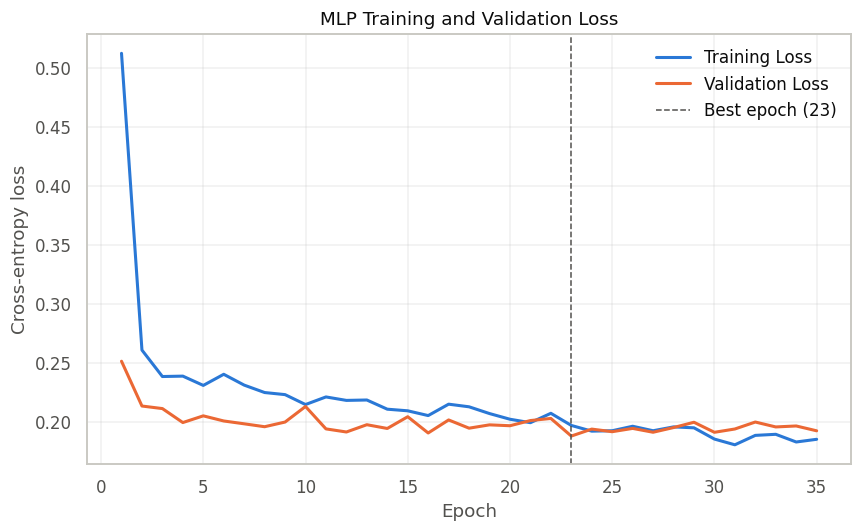

Best epoch: 23
Best validation loss: 0.1877
Training loss at the best epoch: 0.1967


In [47]:
# Learning curves: training vs validation loss
epochs_range = range(1, len(train_losses) + 1)
best_epoch = val_losses.index(min(val_losses)) + 1

plt.figure(figsize=(8, 5))

plt.plot(epochs_range, train_losses, color=BLUE, lw=2, label="Training Loss")
plt.plot(epochs_range, val_losses, color=ORANGE, lw=2, label="Validation Loss")
plt.axvline(best_epoch, color=MUTED, linestyle="--", lw=1,
            label=f"Best epoch ({best_epoch})")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("MLP Training and Validation Loss")

plt.legend(frameon=False)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/fig9_mlp_learning_curves.png")
plt.show()

print("Best epoch:", best_epoch)
print("Best validation loss:", round(min(val_losses), 4))
print("Training loss at the best epoch:", round(train_losses[best_epoch - 1], 4))


**Overfitting / underfitting check:** Both losses drop quickly and then level off at about 0.19-0.20, and the two curves stay close together. The validation loss does not start rising while the training loss keeps falling, so there is no clear sign of overfitting; at the best epoch (23) the validation loss (0.1877) is close to the training loss (0.1967). The validation loss is slightly lower than the training loss because the training loss is averaged over each epoch while the weights are still changing (and batch normalization uses mini-batch statistics), whereas the validation loss is computed in evaluation mode. The model is also not underfitting, because its validation Macro F1 (0.9432) is higher than that of Logistic Regression and Random Forest. Early stopping (patience 12, best weights restored), weight decay, batch normalization, and the learning-rate scheduler were used to control overfitting.

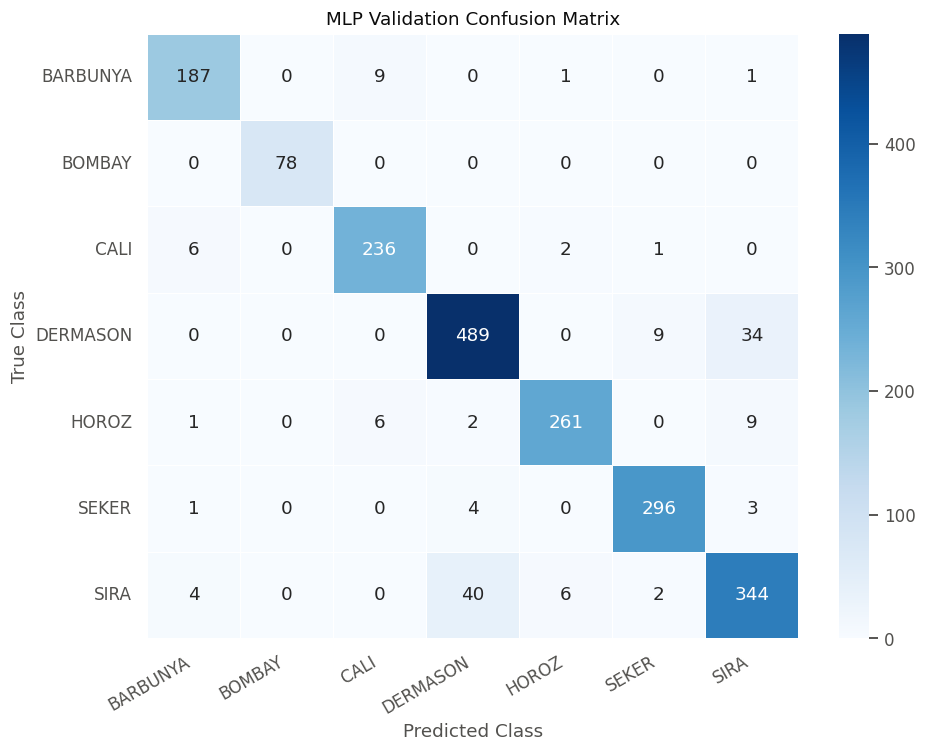

In [48]:
# Confusion Matrix (validation)
cm = confusion_matrix(y_val_true, y_val_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MLP Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(
    "figures/fig12_mlp_validation_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

### 17.9 Final MLP Test Evaluation

The final MLP model is tested on the unseen test dataset.

In [49]:
# Evaluate the final MLP model on the test set
nn_test_probs = predict_probs(model, X_test_tensor)
nn_test_pred = nn_test_probs.argmax(axis=1)

print("Test samples:", len(y_test))
print("Probability check:", np.allclose(nn_test_probs.sum(axis=1), 1, atol=1e-3))

test_scores = mlp_metrics(y_test, nn_test_probs)

print("\nMLP Test Results")
print("-" * 40)
for name, value in test_scores.items():
    print(f"{name}: {value:.4f}")

print("\nTest Classification Report:")
print(classification_report(y_test, nn_test_pred, target_names=class_names, digits=4))

Test samples: 2032
Probability check: True

MLP Test Results
----------------------------------------
Accuracy: 0.9262
Macro Precision: 0.9367
Macro Recall: 0.9383
Macro F1: 0.9372
ROC-AUC (OvR): 0.9949

Test Classification Report:
              precision    recall  f1-score   support

    BARBUNYA     0.9196    0.9242    0.9219       198
      BOMBAY     1.0000    1.0000    1.0000        78
        CALI     0.9249    0.9551    0.9398       245
    DERMASON     0.9393    0.9023    0.9204       532
       HOROZ     0.9810    0.9247    0.9520       279
       SEKER     0.9299    0.9605    0.9450       304
        SIRA     0.8623    0.9015    0.8815       396

    accuracy                         0.9262      2032
   macro avg     0.9367    0.9383    0.9372      2032
weighted avg     0.9273    0.9262    0.9264      2032



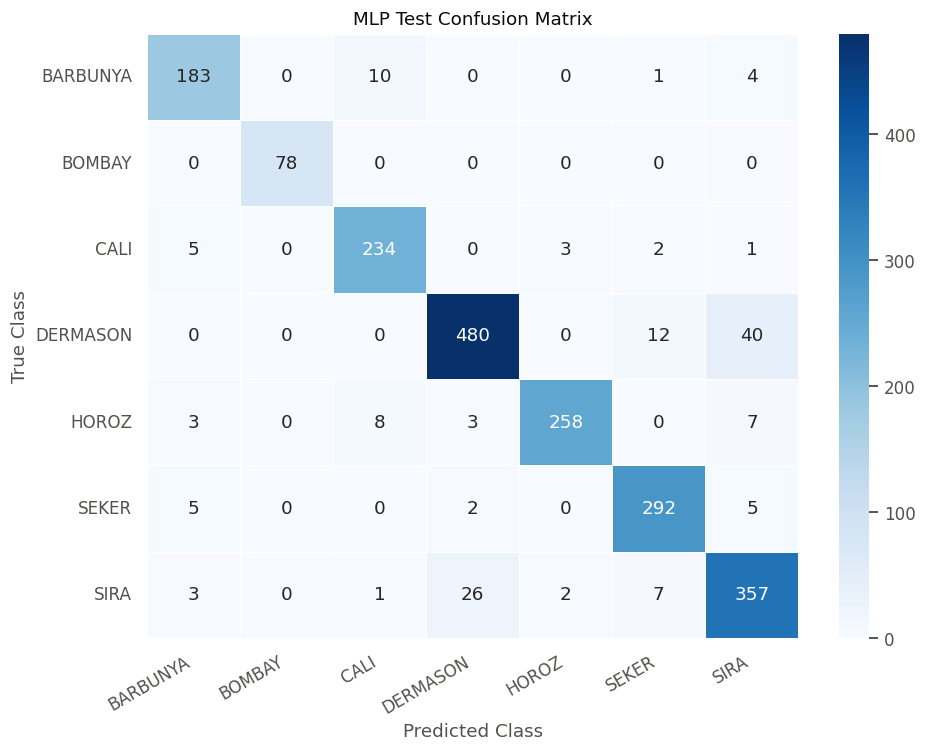

In [50]:
# Confusion Matrix (test)
test_cm = confusion_matrix(y_test, nn_test_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MLP Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(
    "figures/fig13_mlp_test_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

pd.DataFrame(test_cm, index=class_names, columns=class_names).to_csv(
    "results/mlp_test_confusion_matrix.csv")

In [51]:
# Save the final model so it is not lost when the session closes
torch.save(
    {
        "state_dict": model.state_dict(),
        "config": best_config,
        "selected_features": selected_features,
        "class_names": class_names
    },
    "results/mlp_final_model.pt"
)
print("Model saved to results/mlp_final_model.pt")

Model saved to results/mlp_final_model.pt


## 18. Final Model Comparison on the Test Set

This section compares the three models (Logistic Regression, Random Forest, and Neural Network) using the same held-out test set.

The comparison function is defined below and will be executed after the Neural Network is finalized and its test prediction probabilities are available.

In [52]:
def make_final_test_comparison(nn_test_probs):
    """Compare the three finalized models using the held-out test set."""
    nn_test_probs = np.asarray(nn_test_probs, dtype=float)
    expected_shape = (len(y_test), len(class_names))
    if nn_test_probs.shape != expected_shape:
        raise ValueError(f"Expected NN probabilities of shape {expected_shape}, got {nn_test_probs.shape}")
    if not np.isfinite(nn_test_probs).all() or not np.allclose(nn_test_probs.sum(axis=1), 1, atol=1e-3):
        raise ValueError("NN output must contain finite 7-class softmax probabilities (rows summing to 1).")
    def score_probs(model_name, pred, proba):
        return {
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, pred),
            "Macro Precision": precision_score(y_test, pred, average="macro", zero_division=0),
            "Macro Recall": recall_score(y_test, pred, average="macro", zero_division=0),
            "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
            "ROC-AUC (OvR)": roc_auc_score(y_test, proba, multi_class="ovr", average="macro")
        }
    # Evaluate all three final models once, using the identical test split.
    logreg_test_probs = logreg.predict_proba(X_test_raw)
    rf_test_probs = rf_best_model.predict_proba(X_test_raw)
    rows = [
        score_probs("Logistic Regression", logreg.predict(X_test_raw), logreg_test_probs),
        score_probs("Random Forest", rf_best_model.predict(X_test_raw), rf_test_probs),
        score_probs("Neural Network", nn_test_probs.argmax(axis=1), nn_test_probs),
    ]
    final_table = pd.DataFrame(rows).set_index("Model").sort_values("Macro F1", ascending=False)
    display(final_table.round(4))
    final_table.to_csv("results/final_test_model_comparison.csv")
    print("Best test Macro F1:", final_table.index[0])
    return final_table

In [53]:
final_comparison = make_final_test_comparison(nn_test_probs)

,Accuracy,Macro Precision,Macro Recall,Macro F1,ROC-AUC (OvR)
Model,,,,,
Neural Network,0.9262,0.9367,0.9383,0.9372,0.9949
Random Forest,0.9193,0.9326,0.9309,0.9316,0.9945
Logistic Regression,0.9154,0.9280,0.9292,0.9285,0.9939


Best test Macro F1: Neural Network


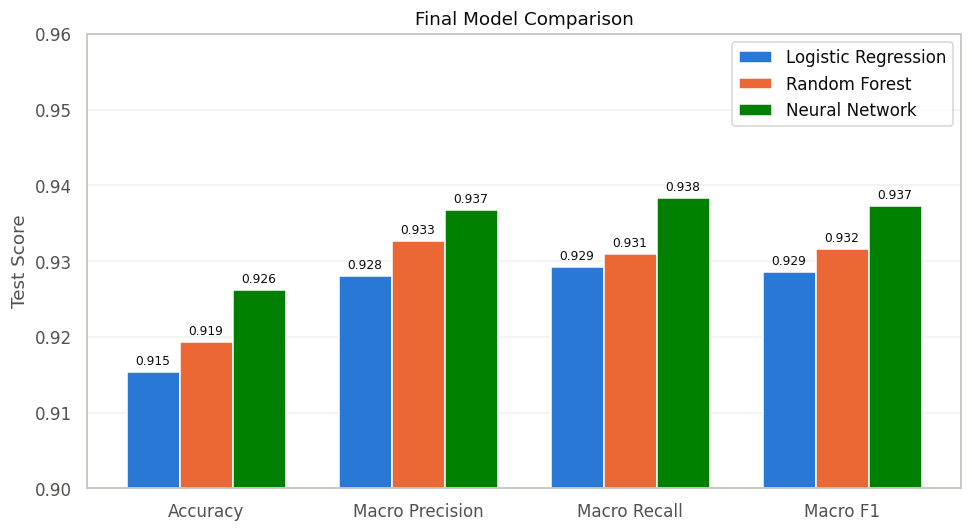

In [54]:
# Final test-set comparison of the three models

metrics = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
models = ["Logistic Regression", "Random Forest", "Neural Network"]
colors = [BLUE, ORANGE, "green"]

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(metrics))
width = 0.25

for i, model in enumerate(models):
    values = final_comparison.loc[model, metrics].astype(float)

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=model,
        color=colors[i]
    )

    # Display values above each bar
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0.90, 0.96)

ax.set_ylabel("Test Score")
ax.set_title("Final Model Comparison")

ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "figures/fig15_test_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 19. Conclusion

- All three models were evaluated once on the same untouched test set (2,032 records), using Macro F1 as the main metric because the classes are imbalanced.
- **The Neural Network (MLP) is the most suitable model**: it achieved the best score on every metric (Accuracy 0.9262, Macro F1 0.9372, ROC-AUC 0.9949), followed by Random Forest (Macro F1 0.9316) and Logistic Regression (Macro F1 0.9285).
- The differences are small, so Logistic Regression remains a good option when a simpler and more interpretable model is preferred.
- The MLP's test Macro F1 is slightly lower than its validation Macro F1 (0.9432) because the validation set was used for early stopping and hyperparameter selection.
- BOMBAY was classified perfectly by the MLP on the test set, while most errors were between SIRA and DERMASON, followed by BARBUNYA and CALI, which have similar size and shape measurements.